In [100]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Subset
from torchmetrics.classification import MulticlassAccuracy, MulticlassConfusionMatrix, MulticlassF1Score

from torchvision import datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [101]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Preparing Data :

In [102]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

In [103]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

In [104]:
train_full = datasets.CIFAR10(
    root="/content/drive/MyDrive/Cifar-10", train=True, download=True,
    transform=train_transform
)

eval_full = datasets.CIFAR10(
    root="/content/drive/MyDrive/Cifar-10", train=True, download=True,
    transform=eval_transform
)

In [105]:
generator = torch.Generator().manual_seed(42)

train_indices, val_indices = random_split(
    range(len(train_full)),
    [45_000, 5_000],
    generator=generator
)

train_data = Subset(train_full, train_indices.indices)
val_data = Subset(eval_full, val_indices.indices)

In [106]:
test_data = datasets.CIFAR10(
    root="/content/drive/MyDrive/Cifar-10", train=False, download=True,
    transform=eval_transform
)

In [107]:
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

### EDA

In [108]:
len(train_data), len(val_data), len(test_data), len(train_data.dataset.classes)

(45000, 5000, 10000, 10)

In [109]:
train_data.dataset.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

6
torch.Size([3, 32, 32])


(np.float64(-0.5), np.float64(31.5), np.float64(31.5), np.float64(-0.5))

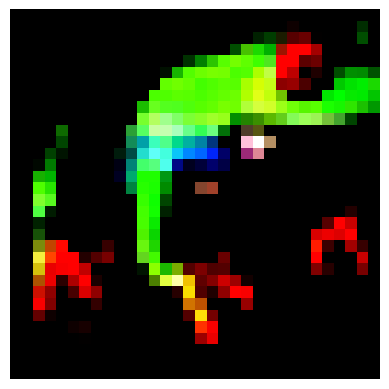

In [110]:
image, label = train_data[0]

print(label)
print(image.shape)

image = image.permute(1,2,0)

plt.imshow(image.clamp(0, 1))
plt.axis('off')

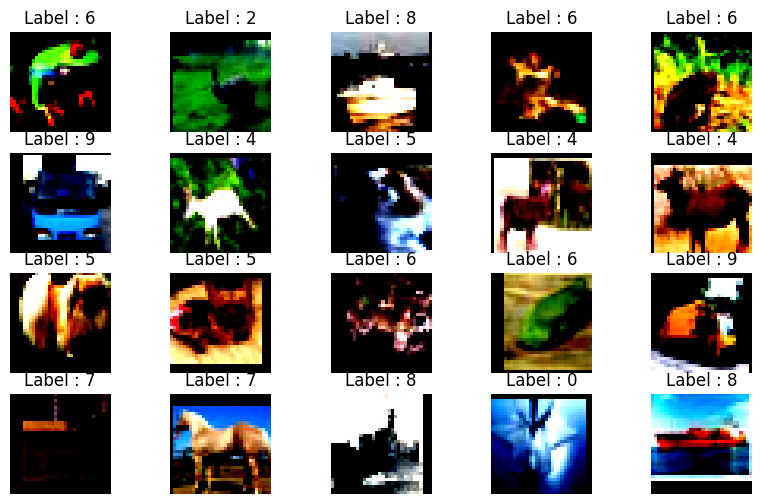

In [111]:
fig, axes = plt.subplots(4, 5, figsize = (10, 6))

for i, ax in enumerate(axes.flat):
  image, label = train_data[i]
  
  ax.imshow(image.permute(1,2,0))
  ax.set_title(f"Label : {label}")
  ax.axis("off")

plt.show()

### Classifier training :

In [112]:
class Cnn(nn.Module):
	def __init__(self, num_classes):
		super().__init__()
		self.feature_extractor = nn.Sequential(
			nn.Conv2d(3, 32, 3, padding=1),
			nn.BatchNorm2d(32),
			nn.ELU(),
			nn.MaxPool2d(2),
			
			nn.Conv2d(32, 64, 3, padding=1),
			nn.BatchNorm2d(64),
			nn.ELU(),
			nn.MaxPool2d(2),


			nn.Conv2d(64, 128, 3, padding=1),
			nn.BatchNorm2d(128),
			nn.ELU(),
			nn.MaxPool2d(2),

			nn.Conv2d(128, 256, 3, padding=1),
			nn.BatchNorm2d(256),
			nn.ELU(),
			nn.MaxPool2d(2),

			nn.Flatten()
		)
		self.classifier = nn.Sequential(
			nn.Linear(256 * 2 * 2, 128),
			nn.BatchNorm1d(128),
			nn.ReLU(),
			nn.Linear(128, num_classes)
		)

	def forward(self, x):
		x = self.feature_extractor(x)
		x = self.classifier(x)
		return x

In [113]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

num_classes = len(train_data.dataset.classes)
model = Cnn(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

In [114]:
num_epochs = 70
best_val_loss = 0.4268
best_state_dict = None

for epoch in range(num_epochs):
	# training :
	model.train()
	train_loss = 0.0

	for images, labels in train_loader:
		images = images.to(device)
		labels = labels.to(device)
		
		optimizer.zero_grad()

		output = model(images)
		loss = criterion(output, labels)

		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	# validation :
	model.eval()
	val_loss = 0.0

	with torch.no_grad():
		for images, labels in val_loader:
			images = images.to(device)
			labels = labels.to(device)

			output = model(images)
			loss = criterion(output, labels)

			val_loss += loss.item()

	train_loss /= len(train_loader)
	val_loss /= len(val_loader)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if val_loss < best_val_loss :
		best_val_loss = val_loss
		best_state_dict = copy.deepcopy(model.state_dict())
		print("saved best model")


epoch : 0 train_loss : 1.2963 val_loss : 1.0801
epoch : 1 train_loss : 0.9664 val_loss : 0.9753
epoch : 2 train_loss : 0.8481 val_loss : 0.7533
epoch : 3 train_loss : 0.7735 val_loss : 0.7117
epoch : 4 train_loss : 0.7266 val_loss : 0.6629
epoch : 5 train_loss : 0.6796 val_loss : 0.6244
epoch : 6 train_loss : 0.6521 val_loss : 0.5914
epoch : 7 train_loss : 0.6200 val_loss : 0.6272
epoch : 8 train_loss : 0.6018 val_loss : 0.6238
epoch : 9 train_loss : 0.5814 val_loss : 0.5529
epoch : 10 train_loss : 0.5637 val_loss : 0.5518
epoch : 11 train_loss : 0.5459 val_loss : 0.5391
epoch : 12 train_loss : 0.5329 val_loss : 0.5468
epoch : 13 train_loss : 0.5226 val_loss : 0.5159
epoch : 14 train_loss : 0.5080 val_loss : 0.5275
epoch : 15 train_loss : 0.4946 val_loss : 0.5097
epoch : 16 train_loss : 0.4925 val_loss : 0.5016
epoch : 17 train_loss : 0.4761 val_loss : 0.4977
epoch : 18 train_loss : 0.4685 val_loss : 0.5008
epoch : 19 train_loss : 0.4541 val_loss : 0.5300
epoch : 20 train_loss : 0.4585

In [115]:
model.load_state_dict(best_state_dict)

<All keys matched successfully>

In [116]:
accuracy = MulticlassAccuracy(num_classes).to(device)
cm = MulticlassConfusionMatrix(num_classes).to(device)
macro_f1 = MulticlassF1Score(num_classes, average='macro').to(device)
micro_f1 = MulticlassF1Score(num_classes, average='micro').to(device)
weighted_f1 = MulticlassF1Score(num_classes, average='weighted').to(device)

model.eval()
test_loss = 0.0

with torch.no_grad():
	for images, labels in test_loader:
		images = images.to(device)
		labels = labels.to(device)

		output = model(images)
		loss = criterion(output, labels)

		accuracy.update(output, labels)
		cm.update(output, labels)
		macro_f1.update(output, labels)
		micro_f1.update(output, labels)
		weighted_f1.update(output, labels)

		test_loss += loss.item()

test_loss /= len(test_loader)
accuracy = accuracy.compute()
cm = cm.compute()
macro_f1 = macro_f1.compute()
micro_f1 = micro_f1.compute()
weighted_f1 = weighted_f1.compute()

print(f"test_loss : {test_loss:.4f}")
print(f"accuracy : {accuracy:.4f}")
print(f" confusion matrix : \n {cm}")
print(f"macro_f1 : {macro_f1:.4f} micro_f1 : {micro_f1:.4f} weighted_f1 : {weighted_f1:.4f}")


test_loss : 0.4342
accuracy : 0.8583
 confusion matrix : 
 tensor([[865,   8,  37,  13,  11,   4,   3,   6,  37,  16],
        [  9, 929,   1,   3,   0,   3,   2,   2,  14,  37],
        [ 31,   1, 797,  62,  46,  33,  20,   7,   1,   2],
        [ 13,   2,  27, 758,  41, 110,  19,  14,   5,  11],
        [  5,   3,  30,  42, 866,  19,  16,  15,   2,   2],
        [ 11,   2,  16, 126,  21, 794,   9,  19,   1,   1],
        [  6,   4,  18,  58,  14,  17, 875,   3,   2,   3],
        [  7,   3,  13,  40,  40,  24,   2, 867,   0,   4],
        [ 29,  11,   7,  10,   3,   3,   2,   4, 919,  12],
        [ 18,  33,   1,   7,   0,   1,   3,   4,  20, 913]], device='cuda:0')
macro_f1 : 0.8593 micro_f1 : 0.8583 weighted_f1 : 0.8593
